# Principal Component Analysis (PCA) to study structural reshaping

We are going to use PCA to study the structural reshaping of the contralateral hemisphere in patients with a brain tumor in the left hemisphere, using grey matter volume as an index of plasticity. As we have X regions within the contralateral hemisphere, we use PCA to reduce the dimensionality, extracting a set of latent variables. This will help us clarify if there are differences in volume between patients healthy participants.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Create colors
emerald='#50C878'
royal='#4169E1'
hunter='#355E3B'

Mounted at /content/drive


We import the libraries

In [ ]:
import numpy as np
from scipy.io import loadmat
import pandas as pd
import matplotlib.pyplot as plt
import math
from sklearn.metrics import roc_auc_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Now we load and read the data

In [ ]:
path='/content/drive/MyDrive/BCBL/Paper_estructura/pca_lucia/'


dict_data = pd.read_csv(path+'structural_pca_data.csv')


Filter the columns to store the right ROIs in the variable 'regions'

In [ ]:
thalamus_index = dict_data.columns.get_loc('thalamus_r')
print(thalamus_index)
regions= dict_data.iloc[:,2:2+54]
regions.shape

group=dict_data.group_type
group = group.to_numpy()
print(type(group))

55
<class 'numpy.ndarray'>


Make a list of ROI names

In [ ]:
region_names=list(regions.columns)
region_names
len(region_names)

54

Turn regions into numpy and filter the database to leave only patients pre and healthy participants (the variable group is not equal to 2)

In [ ]:
X = regions.to_numpy()
np.any(np.isnan(X)) # FALSE means there are no NaNs
print(X.shape)

precon=X[group!=2,:]
print(precon.shape)

(128, 54)
(107, 54)


Calculate the standard deviation of the dataset

#Load and read conducta


In [ ]:
dict_conducta = pd.read_csv('/content/drive/MyDrive/BCBL/Paper_estructura/pca_lucia/beh_progreso.csv')
# dict_conducta.group_type

time= dict_conducta.time
time.to_list()
time_list = time.to_list()
group_type = np.zeros(len(time))

for i, s in enumerate(time_list[0:]):
  if s=='pre':
    group_type[i]=1
  elif s=='post1':
    group_type[i]=2

group_type

keys=['inteligence_progress','wmemory_progress','grammar_progress','production_progress','comprehension_progress']

conducta = np.zeros([len(group_type),len(keys)])

for i,k in enumerate(keys):
  conducta[:,i] = dict_conducta[k]

In [ ]:
conducta_pre = conducta[group_type==1,:]
len(conducta_pre) #37
for i,k in enumerate(keys):
  print(k, 'available:',np.sum(1-np.isnan(conducta_pre[:,i])))


In [ ]:
conducta_post = conducta[group_type==2,:]
len(conducta_post) #37
for i,k in enumerate(keys):
  print(k, 'available:',np.sum(1-np.isnan(conducta_post[:,i])))


# Data normalization

PCA needs the data to be normalised, otherwise, variables with bigger ranges and variation can shadow the importance of the rest.

<div class="alert alert-block alert-info">
<b> With StandardScaler in sklearn, we normalised training data, so each ROI (n=54) has a mean of 0 and a variance of 1. Normalised data is stored in X_norm. </b>
</div>

Before the data normalisation, we divide the participants in training and test.
For training: 40 healthy participants
For test: 30 healthy participants, 37 patients

Now we create the groups, one for the pre data and one for the control data


In [ ]:
pre=X[group==1,:]
print(pre.shape)

controls=X[group==0,:]
print(controls.shape)

post = X[group==2,:]
print(post.shape)

(37, 54)
(70, 54)
(21, 54)


Randomise the controls for training to avoid confounds in the order reflected in the table

In [ ]:
np.random.seed(42)
random_index=np.arange(70)
np.random.shuffle(random_index)
print(random_index) # 22  0 49  4 54 18 10 33 45 12 31

train_controls=40 # it could be used instead of the real number

controls[random_index[:40],:].shape

[22  0 49  4 54 18 10 33 45 12 31  9 67  5 62 30 58 35 57 47 16 34 42 28
  7 53 40 44 46 19 56 39 25 38 13 50  3 17  8 55  6 36 64 69 68 15 27 41
 26 48 24 59 63 11 32 66 61 37 29 43 65  1 52 21  2 23 20 60 14 51]


(40, 54)

Create training and test datasets

In [ ]:
X_train=controls[random_index[:40],:]
print(X_train.shape)

X_test=np.concatenate((controls[random_index[40:],:],pre))
print(X_test.shape)
# Differenciate between controls and pre within the test dataset. Controls=0, Pre=1
labels = np.ones(len(X_test))
labels[:len(controls[40:,:])] = 0
labels

In [ ]:
X_test_prepost=np.concatenate((pre,post))
labels_prepost = np.ones(len(X_test_prepost))
labels_prepost[:len(pre)]=0

X_test_conpost=np.concatenate((controls[random_index[40:],:],post))
labels_conpost = np.ones(len(X_test_conpost))
labels_conpost[:len(controls[40:,:])] = 0


#Normalization.
Use StandardScaler with fit transform to estimate the parameters with the training set

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler(with_mean=True, with_std=True)
X_train_norm = scaler.fit_transform(X_train)
print(X_train_norm.shape)

(40, 54)


Check that all ROI columns have a mean of 0

In [ ]:
print(np.max(np.absolute(X_train_norm.sum(axis=0)))<1e-10)

True


# PCA

In [ ]:
pca = PCA(svd_solver='full') #extract all components
pca.fit(X_train_norm)

PCA(svd_solver='full')

We continue with the rest of the PCA. Now we get how much variance is explained by each component

[0.56884575 0.62731119 0.67744249 0.71934384 0.75154928 0.77924336
 0.80372979 0.82496612 0.84395017 0.86101969 0.87684162 0.89118467
 0.90389211]


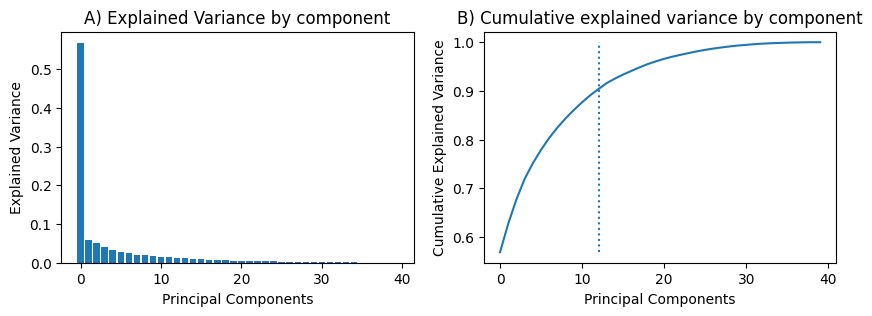

In [ ]:
# Plots the training data
# How much each component explains of the data
plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.bar(range(40),pca.explained_variance_ratio_)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title('A) Explained Variance by component')
# plt.figure()
# The cumulative explaining (taking the first, plus the second etc, you explain more)
cumsum=np.cumsum(pca.explained_variance_ratio_)

plt.subplot(1,2,2)
plt.plot(cumsum)
plt.xlabel('Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('B) Cumulative explained variance by component')
# Print to see where its explainint at least 90%
# Checking manually, we see we need 12 components to explain 90%

plt.vlines(12,cumsum[0],1,ls=':')
print(cumsum[:13])

In [ ]:
for ratio in pca.explained_variance_ratio_:
  print('{:.4f}'.format(ratio))

In [ ]:
# It gives you the minimum to explain the data (40 subjects, 40 components)
# Same data, different domain
scores_train=pca.transform(X_train_norm)
scores_train.shape

(40, 40)

Plot the contribution of each region to the 1st component

['postcentral_r',
 'frontal_mid_r',
 'supramarginal_r',
 'angular_r',
 'rolandic_oper_r',
 'temporal_mid_r',
 'frontal_inf_oper_r',
 'temporal_sup_r',
 'precentral_r',
 'frontal_inf_tri_r',
 'frontal_sup_r',
 'parietal_inf_r',
 'insula_r',
 'precuneus_r',
 'cingulum_mid_r',
 'supp_motor_area_r',
 'frontal_inf_orb_r',
 'fusiform_r',
 'cuneus_r',
 'frontal_sup_medial_r',
 'temporal_pole_sup_r',
 'parietal_sup_r',
 'rectus_r',
 'cingulum_ant_r',
 'cerebelum_crus1_r',
 'lingual_r',
 'frontal_med_orb_r',
 'occipital_sup_r',
 'occipital_mid_r',
 'temporal_inf_r',
 'paracentral_lobule_r',
 'cerebelum_6_r',
 'frontal_sup_orb_r',
 'putamen_r',
 'olfactory_r',
 'heschl_r',
 'parahippocampal_r',
 'cerebelum_10_r',
 'calcarine_r',
 'caudate_r',
 'cerebelum_crus2_r',
 'occipital_inf_r',
 'cerebelum_4_5_r',
 'cerebelum_7b_r',
 'thalamus_r',
 'temporal_pole_mid_r',
 'amygdala_r',
 'hippocampus_r',
 'frontal_mid_orb_r',
 'cingulum_post_r',
 'cerebelum_3_r',
 'cerebelum_8_r',
 'cerebelum_9_r',
 'pallid

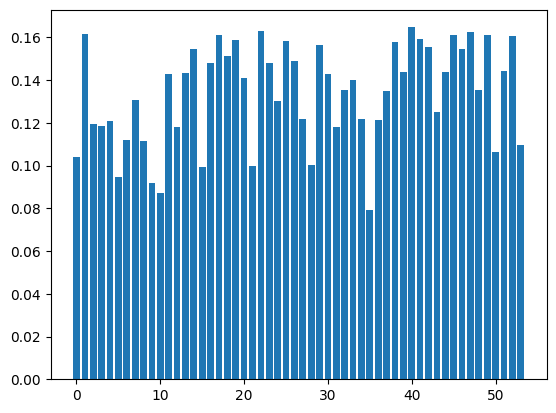

In [ ]:

# Autovectors, contribution of each region to each components
svalues = pca.components_
svalues.shape
# Plot the 1st component
plt.bar(range(54),svalues[0,:])
# Order the regions according to the contribution to the first component
componente1_order = np.argsort(svalues[0,:])[::-1]
componente1_order
sorted_region_names_1 = [region_names[i] for i in componente1_order.tolist()]
sorted_region_names_1

In [ ]:
redscores_train=scores_train.copy()
redscores_train[:,3+1:]=0 # 3 components
recovered_train = pca.inverse_transform(redscores_train)
rec_error_train=(np.square(X_train_norm - recovered_train)).mean(axis=0)
print(rec_error_train.shape)

roi_train_order = np.argsort(rec_error_train)[::-1]
sorted_roi_train = [region_names[i] for i in roi_train_order.tolist()]
sorted_roi_train[:5]

for i,reg_name in enumerate(sorted_roi_train[:]):
  print(reg_name, '- error: {0:.2f} percentage: {1:.2f}'.format(rec_error_train[roi_train_order[i]], rec_error_train[roi_train_order[i]]/np.sum(rec_error_train)))

# TEST
First normalise the test subset and then go to the PCA model

In [ ]:
# Normalisation of the test subset
# Using the scaler transformed with the training data
X_test_norm=scaler.transform(X_test)
print(X_test_norm.shape)

(67, 54)


PCA model for the test subset

In [ ]:
scores_test=pca.transform(X_test_norm)
# 67 subjects, 40 components that we got in the training phase
scores_test.shape

(67, 40)

We take 12 components found in the training phase, we store it in the reduced scores variable

In [ ]:
# redscores_test=scores_test[:,:12]

# Now we trick redscores. We leave the original values for the 12 components and the rest is 0
# Here redscores is a copy of the original
# Finally we take 3 components
redscores_test=scores_test.copy()
# clean after 12 (0s)
redscores_test[:,3:]=0
redscores_test[0,:]

After selecting 12 twelve components, we go back to look into regions

In [ ]:
# Back to regions (from pca domain to region domain)
recovered_data = pca.inverse_transform(redscores_test)
recovered_data.shape

(67, 54)

Now we want to see the reconstruction error

Text(0.5, 1.0, 'D)Reconstruction Error per participant')

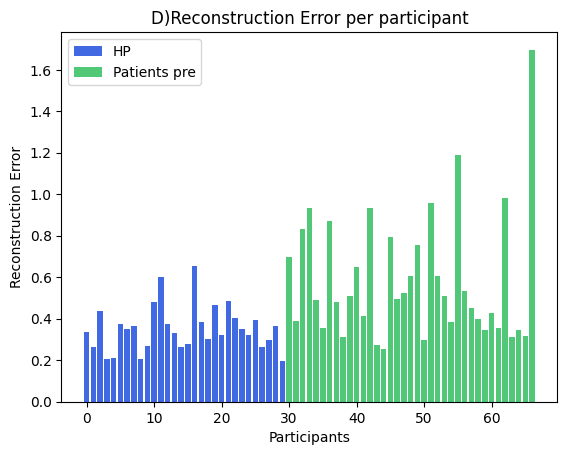

In [ ]:
rec_error=(np.square(X_test_norm - recovered_data)).mean(axis=1)
rec_error.shape
# Plot the reconstruction error for each subject
plt.bar(range(30),rec_error[:30], label='HP', color = royal)
plt.bar(range(30,30+len(rec_error[30:])),rec_error[30:],label='Patients pre', color = emerald)
plt.legend()
plt.xlabel('Participants')
plt.ylabel('Reconstruction Error')
plt.title("D)Reconstruction Error per participant")

NameError: name 'tumor_grade_level' is not defined

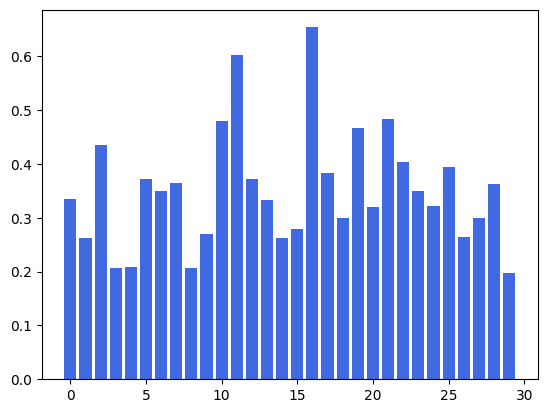

In [ ]:
# Rconstruction error by tumor grade (aöadido por mi no esta funcionando nada de nada)

grade_colors = {
    1: 'gold',
    2: 'orange',
    3: 'red'
}

plt.bar(range(30), rec_error[:30], label='HP', color=royal)

start_idx = 30
patient_indices = np.arange(start_idx, len(rec_error))

for grade, color in grade_colors.items():
    idx = patient_indices[tumor_grade_level[start_idx:] == grade]
    plt.bar(idx, rec_error[idx], color=color, label=f'Grade {grade}')


    plt.legend()
plt.xlabel('Participants')
plt.ylabel('Reconstruction Error')
plt.title("D) Reconstruction Error per participant")
plt.show()


Text(0.5, 1.0, 'Histogram of reconstruction error per group')

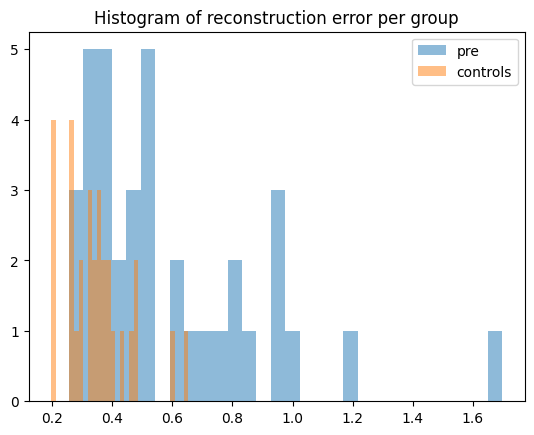

In [ ]:
plt.hist(rec_error[30:],alpha=0.5,label='pre',bins=30)
plt.hist(rec_error[:30],alpha=0.5,label='controls',bins=30)
plt.legend()
plt.title('Histogram of reconstruction error per group')


<BarContainer object of 67 artists>

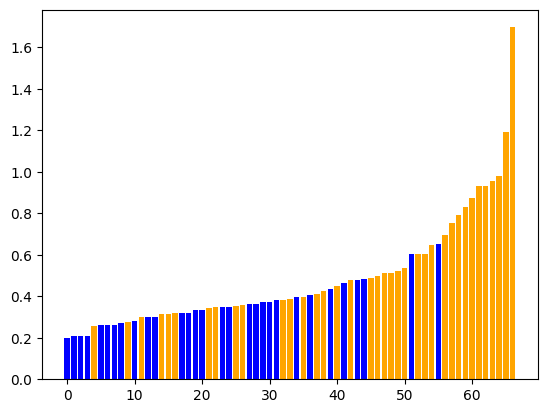

In [ ]:
sorted_rec_error = np.argsort(rec_error)
rec_error_labels=np.ones(67,dtype='int')
rec_error_labels[:30]=0
colors=['blue','orange']
color_list = [colors[s] for s in rec_error_labels[sorted_rec_error]]
plt.bar(range(67),rec_error[sorted_rec_error],color=color_list)
# plt.bar(np.argwhere(rec_error_labels[sorted_rec_error]==0)[:,0],rec_error[sorted_rec_error[rec_error_labels==0]])
# plt.bar(np.argwhere(rec_error_labels[sorted_rec_error]==1)[:,0],rec_error[sorted_rec_error[rec_error_labels==1]])
# plt.bar(sorted_rec_error[30:],rec_error[sorted_rec_error[30:]])

In [ ]:
np.argwhere(rec_error_labels[sorted_rec_error]==0)[:,0].shape

(30,)

# Area under the ROC curve

In [ ]:
# AUC ROC using rec_error
auc=roc_auc_score(labels,rec_error)
print(auc)

0.7828828828828829


In [ ]:
#AUC just one component
auc=roc_auc_score(labels,scores_test[:,0])
print(auc)

0.49909909909909916


# Reconstruction error in the regions for CONTROLS
Which regions contribute more to this clasification

['cerebelum_10_r',
 'temporal_pole_mid_r',
 'cerebelum_9_r',
 'putamen_r',
 'cingulum_post_r']

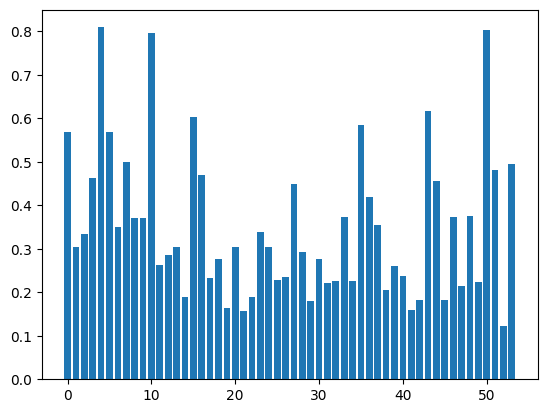

In [ ]:
# Error in the ROIs for CONTROLS
# With recovered_data

recerror_roi_con=(np.square(X_test_norm[0:30,:] - recovered_data[0:30,:])).mean(axis=0)
recerror_roi_con.shape
plt.bar(range(54),recerror_roi_con)

# Order the regions according to the contribution to the first component
roi_con_order = np.argsort(recerror_roi_con)[::-1]
sorted_roi_con = [region_names[i] for i in roi_con_order.tolist()]
sorted_roi_con[:5]
# ['cerebelum_10_r',
#  'temporal_pole_mid_r',
#  'cerebelum_9_r',
#  'putamen_r',
#  'cingulum_post_r']

# Reconstruction error in the regions for PATIENTS

['temporal_pole_mid_r', 'olfactory_r', 'amygdala_r', 'temporal_pole_sup_r', 'cerebelum_9_r']
temporal_pole_mid_r - error: 1.43 percentage: 0.05
olfactory_r - error: 1.22 percentage: 0.04
amygdala_r - error: 1.15 percentage: 0.04
temporal_pole_sup_r - error: 1.10 percentage: 0.03
cerebelum_9_r - error: 1.06 percentage: 0.03
cerebelum_7b_r - error: 1.02 percentage: 0.03
thalamus_r - error: 0.99 percentage: 0.03
hippocampus_r - error: 0.98 percentage: 0.03
putamen_r - error: 0.98 percentage: 0.03
cingulum_post_r - error: 0.96 percentage: 0.03
pallidum_r - error: 0.93 percentage: 0.03
rectus_r - error: 0.89 percentage: 0.03
supp_motor_area_r - error: 0.83 percentage: 0.03
temporal_inf_r - error: 0.76 percentage: 0.02
cerebelum_6_r - error: 0.76 percentage: 0.02
frontal_sup_orb_r - error: 0.75 percentage: 0.02
cerebelum_3_r - error: 0.70 percentage: 0.02
paracentral_lobule_r - error: 0.69 percentage: 0.02
cerebelum_10_r - error: 0.67 percentage: 0.02
calcarine_r - error: 0.66 percentage: 0.

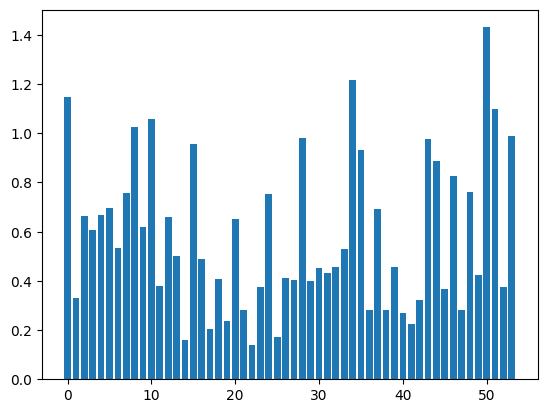

In [ ]:
# Error in the ROIs for PATIENTS PRE
# With recovered_data

recerror_roi_pre=(np.square(X_test_norm[-37:,:] - recovered_data[-37:,:])).mean(axis=0)
recerror_roi_pre.shape
plt.bar(range(54),recerror_roi_pre)

# Order the regions according to the contribution to the first component
roi_pre_order = np.argsort(recerror_roi_pre)[::-1]
sorted_roi_pre = [region_names[i] for i in roi_pre_order.tolist()]
print(sorted_roi_pre[:5])
# ['temporal_pole_mid_r',
#  'olfactory_r',
#  'amygdala_r',
#  'temporal_pole_sup_r',
#  'cerebelum_9_r']

for i,reg_name in enumerate(sorted_roi_pre[:]):
  print(reg_name, '- error: {0:.2f} percentage: {1:.2f}'.format(recerror_roi_pre[roi_pre_order[i]], recerror_roi_pre[roi_pre_order[i]]/np.sum(recerror_roi_pre)))


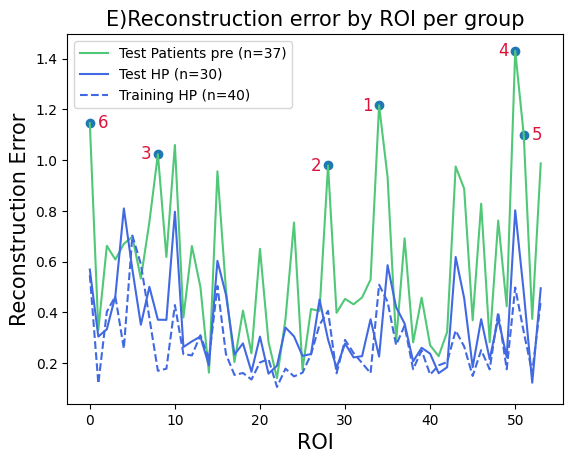

In [ ]:
## Gráfica pero hecha más bonito

# Error por regiones
lw=2 # Se lo he quitado el lw
fontsize=15
plt.plot(recerror_roi_pre, label='Test Patients pre (n=37)', color=emerald)
plt.plot(recerror_roi_con, label='Test HP (n=30)', color=royal)
plt.plot(rec_error_train, label='Training HP (n=40)', color=royal, linestyle='--')
plt.ylabel('Reconstruction Error',fontsize=fontsize)
plt.xlabel('ROI',fontsize=fontsize)
plt.title('E)Reconstruction error by ROI per group',fontsize=fontsize)
plt.legend(fontsize=fontsize-5)

#Esto se calcula y muestra en la siguiente celda, está repetido aqui para poner los marcadores
recerror_corrected=np.square(recerror_roi_pre-recerror_roi_con)
roi_cor_order = np.argsort(recerror_corrected)[::-1]

plt.scatter(roi_cor_order[0:6],recerror_roi_pre[roi_cor_order[0:6]])
position=2*np.array([-1,-1,-1,-1,0.5,0.5])
for i in range(6):
  plt.text(roi_cor_order[i]+position[i] ,recerror_roi_pre[roi_cor_order[i]]-0.02, str(i+1), color="crimson", fontsize=12)


# Error  pre - HP error


olfactory_r 0.17
hippocampus_r 0.08
cerebelum_7b_r 0.08
temporal_pole_mid_r 0.07
temporal_pole_sup_r 0.07
amygdala_r 0.06


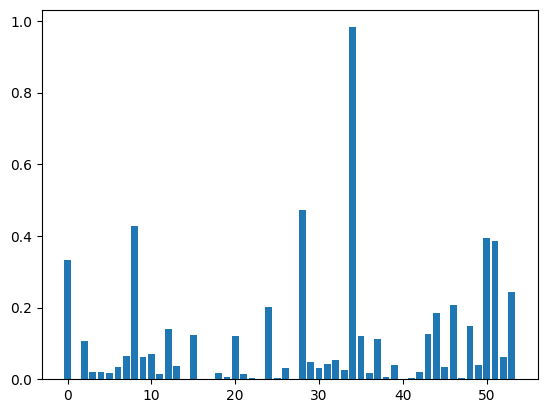

In [ ]:
recerror_corrected=np.square(recerror_roi_pre-recerror_roi_con)
plt.bar(range(54),recerror_corrected)

# Order the regions according to the contribution to the first component
roi_cor_order = np.argsort(recerror_corrected)[::-1]
sorted_roi_cor = [region_names[i] for i in roi_cor_order.tolist()]
for i,reg_name in enumerate(sorted_roi_cor[:6]):
  print(reg_name, '{0:.2f}'.format(recerror_corrected[roi_cor_order[i]]/np.sum(recerror_corrected)))

#  olfactory_r 0.17
# hippocampus_r 0.08
# cerebelum_7b_r 0.08
# temporal_pole_mid_r 0.07
# temporal_pole_sup_r 0.07

temporal_pole_mid_r 0.11
cerebelum_7b_r 0.09
temporal_pole_sup_r 0.07
olfactory_r 0.06
putamen_r 0.05


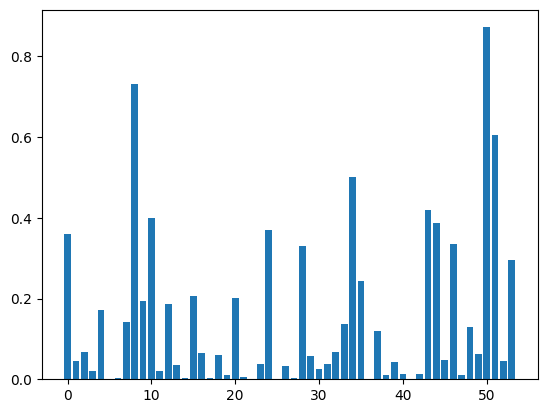

In [ ]:
# dif error pacientes y controles (controles de entrenamiento y controles de test)
recerror_corrected=np.square(recerror_roi_pre-rec_error_train)
plt.bar(range(54),recerror_corrected)

# Order the regions according to the contribution to the first component
roi_cor_order = np.argsort(recerror_corrected)[::-1]
sorted_roi_cor = [region_names[i] for i in roi_cor_order.tolist()]
for i,reg_name in enumerate(sorted_roi_cor[:5]):
  print(reg_name, '{0:.2f}'.format(recerror_corrected[roi_cor_order[i]]/np.sum(recerror_corrected)))

# temporal_pole_mid_r 0.11
# cerebelum_7b_r 0.09
# temporal_pole_sup_r 0.07
# olfactory_r 0.06
# putamen_r 0.05

In [ ]:
rec_error_train.shape

(54,)

In [ ]:
recerror_corrected[0]/np.sum(recerror_corrected)

np.float64(0.04401560203777108)

# Feature space plot

Text(0.5, 1.0, 'D) Reconstruction Error per participant')

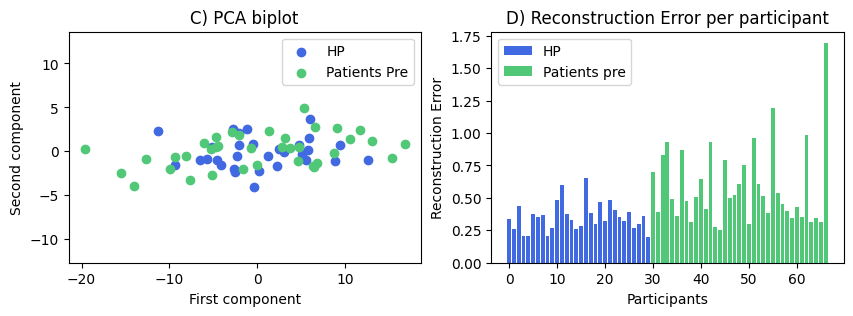

In [ ]:
emerald='#50C878'
royal='#4169E1'

plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.scatter(redscores_test[labels==0,0],redscores_test[labels==0,1], label= 'HP', color = royal)
plt.scatter(redscores_test[labels==1,0],redscores_test[labels==1,1], label= 'Patients Pre', color=emerald)
plt.title('C) PCA biplot')
plt.xlabel('First component'), plt.ylabel('Second component')
plt.axis('equal')
plt.legend()

# Añadir plot reconstruction error by participant
plt.subplot(1,2,2)
rec_error=(np.square(X_test_norm - recovered_data)).mean(axis=1)
rec_error.shape
# Plot the reconstruction error for each subject
plt.bar(range(30),rec_error[:30], label='HP', color = royal)
plt.bar(range(30,30+len(rec_error[30:])),rec_error[30:],label='Patients pre', color = emerald)
plt.legend()
plt.xlabel('Participants')
plt.ylabel('Reconstruction Error')
plt.title("D) Reconstruction Error per participant")


# Pre vs Post

[[13]
 [15]
 [20]]


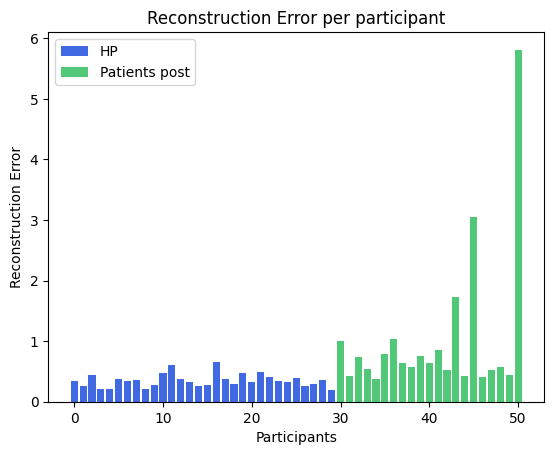

In [ ]:
# plt.bar(range(len(rec_error_subset)),rec_error_subset)

rec_error=(np.square(X_test_norm - recovered_data)).mean(axis=1)
rec_error.shape
# Plot the reconstruction error for each subject
plt.bar(range(30),rec_error_subset[:30], label='HP', color = royal)
plt.bar(range(30,30+len(rec_error_subset[30:])),rec_error_subset[30:],label='Patients post', color = emerald)
plt.legend()
plt.xlabel('Participants')
plt.ylabel('Reconstruction Error')
plt.title("Reconstruction Error per participant")

print(np.argwhere(rec_error_subset>1.2)-30)

Text(0.5, 1.0, 'Histogram of reconstruction error per group')

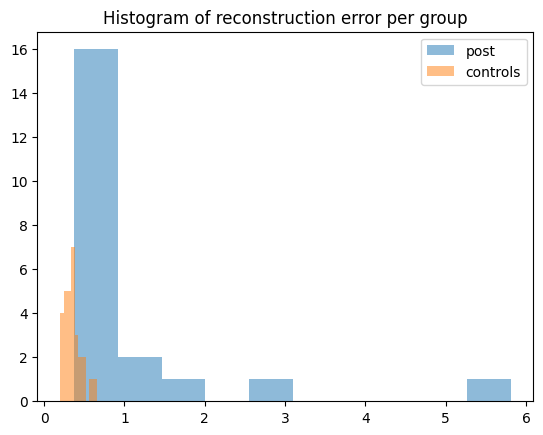

In [ ]:
plt.hist(rec_error_subset[30:],alpha=0.5,label='post')
plt.hist(rec_error_subset[:30],alpha=0.5,label='controls')
plt.legend()
plt.title('Histogram of reconstruction error per group')


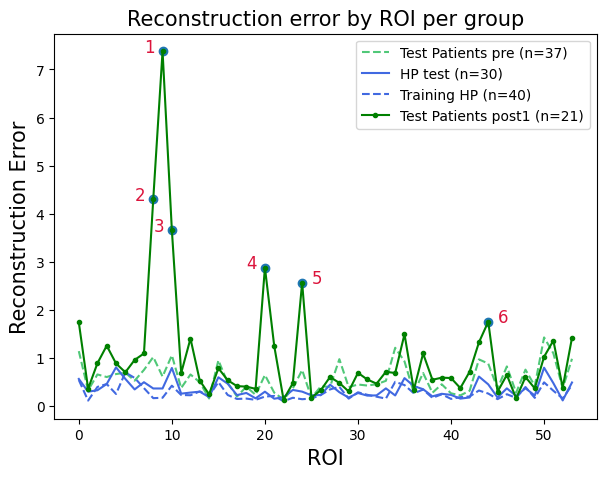

In [ ]:
# Figura de error de reconstrucción para cada ROI separado por grupos (incluyendo Post1)
plt.figure(figsize=(7,5))
# Error por regiones
# grid=5*np.linspace(1,54,54)

plt.plot(recerror_roi_pre, label='Test Patients pre (n=37)', color=emerald, linestyle='--')
plt.plot(recerror_roi_con, label='HP test (n=30)', color=royal, linestyle='-')
plt.plot(rec_error_train, label='Training HP (n=40)', color=royal, linestyle='--')
plt.plot(rec_error_roi_post, label='Test Patients post1 (n=21)', color='green', marker='.')

# plt.ylim(0,4)
plt.ylabel('Reconstruction Error',fontsize=fontsize)
plt.xlabel('ROI',fontsize=fontsize)
plt.title('Reconstruction error by ROI per group',fontsize=fontsize)
plt.legend(fontsize=fontsize-5)

#Esto se calcula y muestra en la siguiente celda, está repetido aqui para poner los marcadores
recerror_corrected=np.square(rec_error_roi_post-recerror_roi_con)
roi_cor_order = np.argsort(recerror_corrected)[::-1]

plt.scatter(roi_cor_order[0:6],rec_error_roi_post[roi_cor_order[0:6]])
position=2*np.array([-1,-1,-1,-1,0.5,0.5])
for i in range(6):
  plt.text(roi_cor_order[i]+position[i] ,rec_error_roi_post[roi_cor_order[i]]-0.02, str(i+1), color="crimson", fontsize=12)



In [ ]:
# Area bajo la curva ROC con Post1
auc=roc_auc_score(subset_label,rec_error_subset)
print(auc)

0.9301587301587301


cerebelum_8_r 0.41
cerebelum_7b_r 0.15
frontal_med_orb_r 0.09
amygdala_r 0.05
frontal_sup_orb_r 0.04
temporal_pole_sup_r 0.03


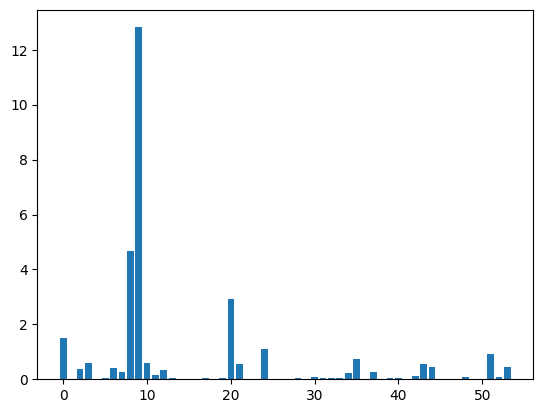

In [ ]:
# Regiones con más error en los Post1 (Post1-Controles Test)

recerror_corrected=np.square(rec_error_roi_post_nooutlier-recerror_roi_con)
plt.bar(range(54),recerror_corrected)

# Order the regions according to the contribution to the first component
roi_cor_order = np.argsort(recerror_corrected)[::-1]
sorted_roi_cor = [region_names[i] for i in roi_cor_order.tolist()]
for i,reg_name in enumerate(sorted_roi_cor[:6]):
  print(reg_name, '{0:.2f}'.format(recerror_corrected[roi_cor_order[i]]/np.sum(recerror_corrected)))

([<matplotlib.axis.XTick at 0x7ab5c350e750>,
 [Text(1.5, 0, 'amygdala_r'),
  Text(6.5, 0, 'angular_r'),
  Text(11.5, 0, 'calcarine_r'),
  Text(16.5, 0, 'caudate_r'),
  Text(21.5, 0, 'cerebelum_10_r')])

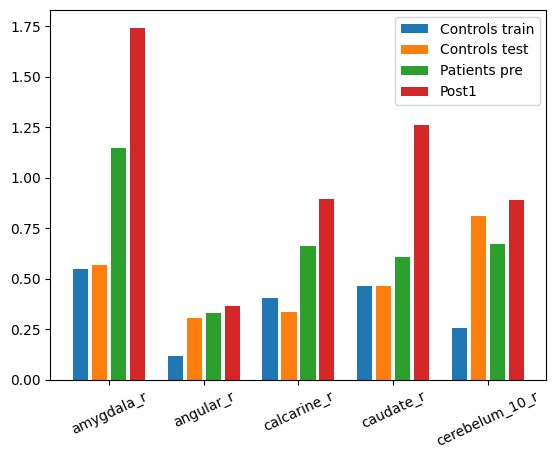

In [ ]:
plt.bar(grid[:5]-5,rec_error_train[:5], label='Controls train')
plt.bar(grid[:5]-4, recerror_roi_con[:5], label='Controls test')
plt.bar(grid[:5]-3, recerror_roi_pre[:5], label='Patients pre')
plt.bar(grid[:5]-2,rec_error_roi_post[:5], label='Post1')
plt.legend()
plt.xticks(grid[:5]-3.5, region_names[:5], rotation=25)


In [ ]:
roi_post_order = np.argsort(rec_error_roi_post)[::-1]
sorted_roi_post = [region_names[i] for i in roi_post_order.tolist()]
print(sorted_roi_post[:5])
# ['temporal_pole_mid_r',
#  'olfactory_r',
#  'amygdala_r',
#  'temporal_pole_sup_r',
#  'cerebelum_9_r']

for i,reg_name in enumerate(sorted_roi_post[:5]):
  print(reg_name, '- error: {0:.2f} percentage: {1:.2f}'.format(rec_error_roi_post[roi_post_order[i]], rec_error_roi_post[roi_post_order[i]]/np.sum(rec_error_roi_post)))


['cerebelum_8_r', 'cerebelum_7b_r', 'cerebelum_9_r', 'frontal_med_orb_r', 'frontal_sup_orb_r']
cerebelum_8_r - error: 7.38 percentage: 0.13
cerebelum_7b_r - error: 4.30 percentage: 0.08
cerebelum_9_r - error: 3.66 percentage: 0.07
frontal_med_orb_r - error: 2.88 percentage: 0.05
frontal_sup_orb_r - error: 2.57 percentage: 0.05
